# Cylindrical refolded isocline — Surfe

Surfe (Hillier et al.), a radial-basis-function interpolant, fitted to the same contacts and
bedding as the LDI fit in `07b_cylindrical_isocline_ldi` and evaluated on the same grid
(`results/inputs.npz`; run 07b first). Computation and diagnostics only; the plots are not
saved. Results go to `results/`. This notebook needs `surfepy` but not `curlew` or `torch`.

**The same data as LDI, nothing more.** Each horizon is only an equality: its contacts share
one value, which is free (the Lajaunie method, `Surfe_API(2)`; the interface levels are plain
labels that group each horizon's points). The scale and the way-up of the field come from
the bedding normals.

**Anisotropy** (`ANISOTROPY`). An isotropic interpolant knows nothing of the fold axis, so
nothing makes it cylindrical. Surfe's way to approach a cylindrical fold is anisotropy: a
range along the hinge `ANISOTROPY` times the range across it (`diagnostics.AnisotropicSurfe`,
along the hinge from 07a). `ANISOTROPY = 1` is default Surfe. Each setting saves under its
own name: `surfe` for 1, `surfe_aniso<ratio>` otherwise (`surfe.npz`, `surfe.json`,
`meshes_surfe.npz`, and so on), so several can be compared.

The diagnostics are those of 07b: interior extrema (zeros of Surfe's analytic gradient), the
younging, the contacts and the units between the horizons against the truth on the same
sections, and the cylindricity. The
horizon surfaces are meshed here (marching cubes) rather than in
`07d_cylindrical_isocline_meshes`, because meshing needs the fitted Surfe model, and that
notebook runs in the curlew kernel.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SURFE_BUILD = Path("../../../../surfe/build").resolve()
if SURFE_BUILD.exists() and str(SURFE_BUILD) not in sys.path:
    sys.path.insert(0, str(SURFE_BUILD))
import surfepy

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
import isocline_inputs
figstyle.apply()

OUT_DIR = isocline_inputs.RESULTS_DIR
data = isocline_inputs.load_processed()
horizons, names = data["horizons"], data["horizon_names"]
gp, gv, hinge = data["gp"], data["gv"], data["hinge"]
inp = np.load(OUT_DIR / "inputs.npz")
x, y, z, sections, box = inp["x"], inp["y"], inp["z"], inp["sections"], inp["box"]
labels = np.arange(len(horizons), dtype=float)     # one label per horizon: it only groups the points
print(f"{len(horizons)} horizons, {sum(len(h) for h in horizons)} contacts, {len(gp)} bedding | "
      f"grid {len(x)} x {len(y)} x {len(z)}")

3 horizons, 102 contacts, 56 bedding | grid 60 x 94 x 80


## Fit

Each contact an interface constraint with its horizon's label; each bedding reading a planar
constraint with its younging normal. As elsewhere: the cubic kernel and a first-order
polynomial.

In [2]:
ANISOTROPY = 1e5       # range along the hinge / range across it; 1 = default (isotropic) Surfe
KERNEL = "r3"          # also: "WendlandC2", "Gaussian", "MaternC4", ...
POLY_ORDER = 1

TAG = "surfe" if ANISOTROPY == 1.0 else f"surfe_aniso{ANISOTROPY:g}"
model = surfepy.Surfe_API(2)
if ANISOTROPY != 1.0:
    model = diagnostics.AnisotropicSurfe(model, hinge, ratio=ANISOTROPY)
for h, label in zip(horizons, labels):
    for px, py, pz in h:
        model.AddInterfaceConstraint(px, py, pz, float(label))
for (px, py, pz), (nx, ny, nz) in zip(gp, gv):
    model.AddPlanarConstraintwNormal(px, py, pz, nx, ny, nz)
model.SetRBFKernel(KERNEL)
model.SetPolynomialOrder(POLY_ORDER)
with diagnostics.quiet():   # Surfe prints progress from C++
    model.ComputeInterpolant()
print("fitted", TAG)

fitted surfe_aniso100000


## Evaluate on the saved grid

Scalar and analytic gradient over the volume. Each horizon's isovalue is the mean of the
field over its contacts, as curlew sets it for LDI.

In [3]:
phi, gradient = diagnostics.evaluate_surfe(model, x, y, z)
isovalues = diagnostics.surfe_isovalues(model, horizons)
print("isovalues:", isovalues.round(3))

isovalues: [-268.742 -281.946 -294.758]


## Diagnostics

In [4]:
N_ALIGN = 1_000
SEED = 404

critical = diagnostics.surfe_critical_points(model, x, y, z, gradient_grid=gradient)
grad_fn = diagnostics.make_surfe_gradient_function(model)
g_bed = grad_fn(gp)
cos = (g_bed * gv).sum(1) / (np.linalg.norm(g_bed, axis=1) * np.linalg.norm(gv, axis=1))
younging = np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))
spread = np.asarray([diagnostics.surfe_scalar(model, h).std() / np.linalg.norm(grad_fn(h), axis=1).mean()
                     for h in horizons])

misfit = isocline_inputs.contact_misfit(x, y, z, phi, isovalues, data["truth_points"], sections)
change = isocline_inputs.unit_change_along_hinge(phi, isovalues)
iou = isocline_inputs.unit_iou(x, y, z, phi, isovalues, data["truth_lines"], sections)
rng = np.random.default_rng(SEED)
flat = gradient.reshape(-1, 3)
alignment = isocline_inputs.hinge_alignment(flat[rng.choice(len(flat), N_ALIGN, replace=False)], hinge)
comparison = {"extrema": critical.counts, "younging_deg_median": float(np.median(younging)),
              "younging_deg_mean": float(younging.mean()), "fraction_reversed": float(np.mean(cos < 0)),
              "contact_spread_m": spread.tolist(), **isocline_inputs.summarise(misfit, change, alignment, iou)}

print(f"{TAG}: 3-D grid search {critical.counts} (it recovers only some of the extrema, which are lines along the hinge; the extrema are counted on the section below)")
print(f"younging angle: median {np.median(younging):.1f}°, mean {younging.mean():.1f}°, reversed {np.mean(cos < 0):.2f}")
print(f"contact spread about its level surface (m): {spread.round(1)}")
print(f"truth contacts to the model: median {comparison['contact_to_model_m_median']:.1f} m, "
      f"90th pct {comparison['contact_to_model_m_p90']:.1f} m | model contacts to the truth: median "
      f"{comparison['isoline_to_truth_m_median']:.1f} m, 90th pct {comparison['isoline_to_truth_m_p90']:.1f} m")
print(f"IoU with the true units between the horizons (H0–H1, H1–H2, ...): "
      f"{np.round(comparison['unit_iou_median'], 2)} (median over the sections)")
print(f"cylindricity: |grad.h|/|grad| median {comparison['hinge_alignment_median']:.2f}, 95th pct "
      f"{comparison['hinge_alignment_p95']:.2f} | unit change along the hinge {comparison['unit_change_along_hinge_mean']:.3f} "
      f"({comparison['unit_change_along_hinge_lines_affected']:.1%} of lines)")

surfe_aniso100000: critical points {'maximum': 8, 'minimum': 6, 'saddle': 6, 'degenerate': 0}
younging angle: median 0.0°, mean 0.0°, reversed 0.00
contact spread about its level surface (m): [0. 0. 0.]
truth contacts to the model: median 4.0 m, 90th pct 17.9 m | model contacts to the truth: median 4.6 m, 90th pct 19.0 m
IoU with the true units between the horizons (H0–H1, H1–H2, ...): [0.69 0.64] (median over the sections)
cylindricity: |grad.h|/|grad| median 0.00, 95th pct 0.00 | unit change along the hinge 0.000 (0.0% of lines)


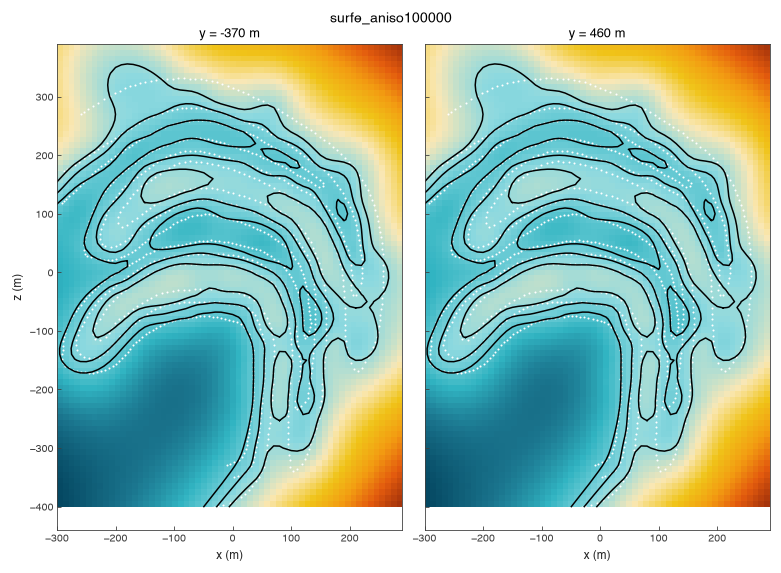

In [5]:
# Quick check (not saved): the scalar on the sections, the model's contacts (black) and the truth (white).
fig, axs = plt.subplots(1, len(sections), figsize=(3.2 * len(sections), 4.6), constrained_layout=True, sharey=True)
for ax, ys in zip(axs, sections):
    j = int(np.argmin(np.abs(y - ys)))
    ax.imshow(phi[:, j, :].T, origin="lower", extent=(x[0], x[-1], z[0], z[-1]), cmap=figstyle.ramp())
    for level in isovalues:
        for l in isocline_inputs.section_contours(x, z, phi[:, j, :], level):
            ax.plot(*l.T, color="k", lw=0.9)
    for p in data["truth_points"]:
        ax.scatter(*p.T, s=1.5, color="w", linewidths=0)
    ax.set(title=f"y = {y[j]:.0f} m", xlabel="x (m)")
axs[0].set_ylabel("z (m)")
fig.suptitle(TAG)
plt.show()

## Isosurfaces

The three horizon surfaces, by marching cubes on a regular grid (scikit-image) over the box,
and the small closed level surface just inside each interior extremum (finer step), for the
figure's enclosures.

In [6]:
STEP = 5.0                                     # m, marching-cubes spacing of the surfaces
SHELL_STEP = 2.0                               # m, and of the small shells round extrema
SHELL_DELTA = 0.08                             # shell level, as a fraction of the level spacing
SHELL_HALF = 40.0                              # m, a shell must close within this distance of its extremum
coarse = diagnostics.surfe_mesher(model, STEP)
fine = diagnostics.surfe_mesher(model, SHELL_STEP)
mesher = lambda level, bounds: (coarse if np.ptp(bounds, axis=0).max() > 2 * SHELL_HALF else fine)(level, bounds)

MESH_PAD_X = 60.0                              # m added to the box on the -x side, so the renders can show
mesh_box = box + np.array([[-MESH_PAD_X, 0.0, 0.0], [0.0, 0.0, 0.0]])   # the closure of the contacts there

extrema = [(p, kind, float(diagnostics.surfe_scalar(model, p[None])[0]))
           for kind in ("maximum", "minimum") for p in critical.of_kind(kind)]
spacing = float(np.min(np.abs(np.diff(isovalues))))
diagnostics.export_meshes(OUT_DIR / f"meshes_{TAG}.npz", mesher, isovalues, mesh_box, extrema=extrema,
                          shell_delta=SHELL_DELTA * spacing, shell_half=SHELL_HALF)
print(f"wrote meshes_{TAG}.npz: {len(isovalues)} surfaces, {len(extrema)} extrema")
# the figure's section, widened like the meshes (07f draws it)
sec_x, sec_y, sec_pts = isocline_inputs.figure_section(x, y, z, horizons, MESH_PAD_X)
sec_phi = diagnostics.surfe_scalar(model, sec_pts).reshape(len(sec_x), len(z))
print(f"section at y = {sec_y:.0f} m, x from {sec_x[0]:.0f} to {sec_x[-1]:.0f} m")
# its interior extrema: zeros of the in-plane gradient, from Surfe's analytic gradient (07f draws them;
# for a cylindrical field each is a line along the hinge)
sec_crit = diagnostics.surfe_critical_points(model, sec_x, z, y=sec_y)
print(f"section critical points: {sec_crit.counts}")
comparison["extrema"] = sec_crit.counts   # the one definition of a cylindrical field's extrema: zeros of the in-plane gradient on this section, as for LDI (07d, 07e)


wrote meshes_surfe_aniso100000.npz: 3 surfaces, 14 extrema
section at y = -30 m, x from -360 to 290 m
section critical points: {'maximum': 16, 'minimum': 11, 'saddle': 27, 'degenerate': 0}


## Save

In [8]:
np.savez_compressed(
    OUT_DIR / f"{TAG}.npz",
    phi=phi.astype(np.float32), isovalues=isovalues, younging_angle=younging,
    section_x=sec_x, section_y=sec_y, section_phi=sec_phi.astype(np.float32),
    unit_change=change.astype(np.float32), unit_iou=iou, hinge_alignment=alignment,
    **{f"misfit_{k}": v for k, v in misfit.items()}, **diagnostics.pack_critical(critical),
    **diagnostics.pack_critical(sec_crit, prefix="section_critical_"),
)
(OUT_DIR / f"{TAG}.json").write_text(json.dumps(
    {"comparison": comparison,
     "parameters": {"anisotropy": ANISOTROPY, "kernel": KERNEL, "poly_order": POLY_ORDER,
                    "interfaces": "one free equality per horizon (Lajaunie); labels only group points"}}, indent=1))
print(f"wrote {TAG}.npz and {TAG}.json to", OUT_DIR)

wrote surfe_aniso100000.npz and surfe_aniso100000.json to results
